In [15]:
import numpy as np
import os
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from skimage.feature import graycomatrix, graycoprops
from sklearn.decomposition import PCA

#### Loading dataset

In [2]:
base_path = "C:\\Users\\Dell\\Desktop\\Nowy folder\\PJATK\\III SEMESTR\\ZUM\\breast-cancer-detection"
split = ["train", "test", "valid"]
classes = ["0", "1"]

def load_datasets(split):
    paths = []
    labels = []
    for label in classes:
        folder = os.path.join(base_path, split, label)
        for img in os.listdir(folder):
            paths.append(os.path.join(folder, img))
            labels.append(label)
    return pd.DataFrame({"path": paths, "label": labels})   

df_train = load_datasets("train")
df_test = load_datasets("test")
df_valid = load_datasets("valid")


In [3]:
img_size = 128

#### Preprocessing for flatten function and radiomics approach

In [11]:
def preprocessing(df):
    X_flat = []
    X_rad = []
    y = []
    for i in tqdm(range(len(df))):
        path = df.iloc[i]["path"]
        label = df.iloc[i]["label"]
    
        img = Image.open(path).convert("L")
        img = img.resize((img_size, img_size))
        arr = np.array(img)
    
        X_flat.append(arr.flatten())
        #prop{‘contrast’, ‘dissimilarity’, ‘homogeneity’, ‘energy’, ‘correlation’, ‘ASM’, ‘mean’, ‘variance’, ‘std’, ‘entropy’}
        g = graycomatrix(arr, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
        contrast = graycoprops(g, "contrast")[0,0]
        dissimilarity = graycoprops(g, "dissimilarity")[0,0]
        homogeneity = graycoprops(g, "homogeneity")[0,0]
        energy = graycoprops(g, "energy")[0,0]
        correlation = graycoprops(g, "correlation")[0,0]
        X_rad.append([contrast, dissimilarity, homogeneity, energy, correlation])
        y.append(0 if label=="0" else 1)
    return np.array(X_flat), np.array(X_rad), np.array(y)

In [12]:
X_train_flat, X_train_rad, y_train = preprocessing(df_train)
X_valid_flat, X_valid_rad, y_valid = preprocessing(df_valid)
X_test_flat,  X_test_rad,  y_test  = preprocessing(df_test)

100%|████████████████████████████████████████████████████████████████████████████████| 336/336 [00:03<00:00, 87.26it/s]


In [14]:
print(X_train_flat.shape, X_train_rad.shape, y_train.shape)

(2372, 16384) (2372, 5) (2372,)


#### Save datasets with pickle

In [16]:
with open("features.pkl", "wb") as f:
    pickle.dump({
        "X_train_flat": X_train_flat,
        "X_train_rad": X_train_rad,
        "y_train": y_train,
        "X_valid_flat": X_valid_flat,
        "X_valid_rad": X_valid_rad,
        "y_valid": y_valid,
        "X_test_flat":  X_test_flat,
        "X_test_rad":  X_test_rad,
        "y_test":  y_test
    }, f)

#### Standarization

In [30]:
scaler = StandardScaler()
X_flat = scaler.fit_transform(X_flat)

In [31]:
X_flat

array([[ 0.4196924 ,  0.44533318,  0.47890294, ...,  2.32302785,
         2.28704581,  2.21072772],
       [ 2.27794728,  2.27555652,  2.25470182, ...,  2.32302785,
         2.28704581,  2.21072772],
       [-0.7022728 , -0.69709922, -0.68574437, ..., -0.61171842,
        -0.66845433, -0.71807662],
       ...,
       [-0.7022728 , -0.69709922, -0.68574437, ...,  0.40105676,
         0.57169671,  0.56830019],
       [ 0.64174802,  0.62019528,  0.50196527, ..., -0.61171842,
        -0.66845433, -0.71807662],
       [-0.7022728 , -0.69709922, -0.68574437, ..., -0.61171842,
        -0.66845433, -0.71807662]], shape=(2372, 16384))

#### Preprocessing for PCA approach

In [40]:
var = np.var(abs(X_flat), axis=0)
print(np.mean(var))

0.3702482427202891


In [43]:
pca = PCA()
pca.fit(X_flat)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


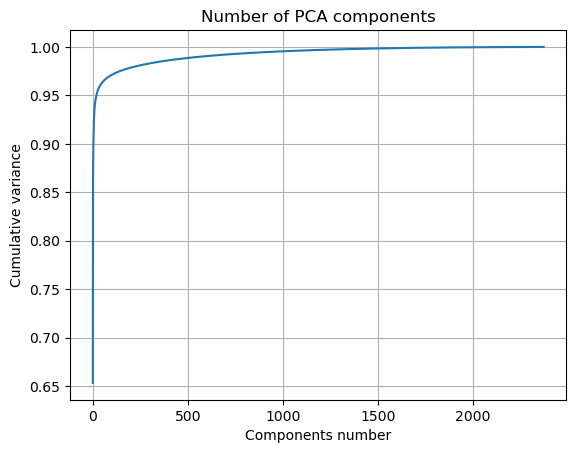

In [48]:
cum_var = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cum_var)
plt.xlabel("Components number")
plt.ylabel("Cumulative variance")
plt.title("Number of PCA components")
plt.grid(True)
plt.show()

In [53]:
n_comp = np.argmax(cum_var >= 0.95) + 1
n_comp

np.int64(20)

Z powyższej analizy wynika, że liczba komponentów wybrana do PCA to 20